# Computing Project 
## 3-Particle Quantum Mechanics

##### connecting to kernel

In [1]:
print('connected')

connected


**Importing Necessary Packages**


In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import numpy as np
import scipy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.special import factorial
# import pandas



#### Defining things

In [4]:
electron_charge = 14.4 ##eVA this is the squared value
r0 = 0.52917 ##A
zed = 2
electron_mass = 0.511
hbar = r0 * electron_mass * electron_charge ##squared value

r0_calc = hbar/(electron_mass * electron_charge)
print(r0_calc)

0.5291699999999999


**Generating n states $\psi$**

In [5]:
hyll_states = [[0,0,0], [0,0,1], [0,2,0]]
one_state_basis = [[0,0,0]]
test_kappa = 1

In [6]:
chosen_states = hyll_states
chosen_num = len(chosen_states)
chosen_kappa = test_kappa

#### Making Matrices N, T, W and C


In [7]:
def generate_matrix(kappa, n, states):
    
    
    hy_lambda = zed /(kappa * r0)


    mat_N = [[0]*n for _ in range(n)]
    mat_W = [[0]*n for _ in range(n)]
    mat_C = [[0]*n for _ in range(n)]
    mat_T = [[0]*n for _ in range(n)]

    for i in range(n): #this will give the number of rows
        for j in range(n):  # this will give the number of cols

            j_1 = states[i][0]  
            j_2 = states[j][0]
            k_1 = states[i][1] 
            k_2 = states[j][1]
            m_1 = states[i][2] 
            m_2 = states[j][2]

            jay = states[i][0] + states[j][0]
            kay = states[i][1] + states[j][1]
            em = states[i][2] + states[j][2]


            def N(J, K, M):
                if M == -2:
                    entry_value_N = 0
                else:   
                    factorial_term = factorial((J + K + M +5), exact = True) #if this needs to be faster, set exact to be false
                    wavelength_term = (1/(2*hy_lambda))**((J+K+M+6))
                    coeff = (2*(np.pi)**2) / (M+2)
                    fraction_sum = (1/(K+1) - 1/(K+3) - 1/(K+M+3) + 1/(K+M+5))
            
                    if K%2 ==0:
                        entry_value_N = factorial_term * coeff * wavelength_term * fraction_sum
                    if K%2 ==1:
                        entry_value_N = 0
                return entry_value_N
            
            def W(J, K, M):
                
                value = (electron_charge)*(N(jay, kay, em-1))
                
                return value
            

            def C(J, K, M):
                if M == -2:
                    entry_value_C = 0
                else:   
                    factorial_term = factorial((J + K + M +4), exact = True) #if this needs to be faster, set exact to be false
                    wavelength_term = (1/(2*hy_lambda))**((J+K+M+5))
                    coeff = (8*(np.pi)**2) / (M+2)
                    fraction_sum = (1/(K+1) - 1/(K+M+3))
                    extra_pre = -zed * electron_charge
            
                    if K%2 ==0:
                        entry_value_C = extra_pre * factorial_term * coeff * wavelength_term * fraction_sum
                    if K%2 ==1:
                        entry_value_C = 0
                return entry_value_C
            
            
            def T(J, K, M, j1, j2, k1, k2, m1, m2):
                extra_pre = -zed * electron_charge
                coeff = (hbar)/(2*electron_mass)
                square_1 = (
                    (hy_lambda**2)*N(jay, kay, em) 
                    - J*hy_lambda*N(jay-1, kay, em) 
                    + j1*j2*N(jay-2, kay, em) 
                    + k1*k2*N(jay,kay-2, em)
                    + m1*m2*N(jay, kay, em-2) 
                )
                square_2 = (
                    -M*hy_lambda*(C(jay, kay, em)/extra_pre - C(jay, kay+2, em-2)/extra_pre)
                    +(m1*j2 + m2*j1)*(C(jay-1, kay, em)/extra_pre - C(jay-1, kay+2, em-2)/extra_pre)
                    +(m1*k2 + m2*k1)*(C(jay+1, kay, em-2)/extra_pre-C(jay-1,kay, em)/extra_pre)
                )
                value = coeff* (
                    2*square_1 + 0.5*square_2
                )
                return value
            
                

            mat_N[i][j] = N(jay, kay, em)
            mat_W[i][j] = W(jay, kay, em)
            mat_C[i][j] = C(jay, kay, em)
            mat_T[i][j] = T(jay, kay, em, j_1, j_2, k_1, k_2, m_1, m_2)
    

    matrices = [mat_N, mat_W, mat_C, mat_T]
    return matrices


In [8]:
N_mat, W_mat, C_mat, T_mat= generate_matrix(test_kappa, chosen_num, chosen_states)

##### Checking Hyllaas' states

In [9]:
## this is to test with the hylleraas states
def correct_N(kappa):
    
    
    lamb = zed /(kappa * r0)

    pre = (np.pi )**2 *(lamb)**(-6)

    correct_mat = [
        [pre                     , pre*(35/16)*(lamb)**(-1) , pre*(3/2)*(lamb)**(-2) ],
        [pre*(35/16)*(lamb)**(-1), pre*(6)*(lamb)**(-2)     , pre*(77/16)*(lamb)**(-3)],
        [pre*(3/2)*(lamb)**(-2)  , pre*(77/16)*(lamb)**(-3) ,pre*(9)*(lamb)**(-4)]
    ]
    
    return correct_mat

def correct_W(kappa):
    
    
    lamb = zed /(kappa * r0)

    pre = electron_charge*5*(np.pi**2)/(8*(lamb**5))
    correct_mat = [
        [pre                     , pre*1.6*(lamb)**(-1) , pre*0.9*(lamb)**(-2) ],
        [pre*(1.6)*(lamb)**(-1), pre*(3.5)*(lamb)**(-2)     , pre*(2.4)*(lamb)**(-3)],
        [pre*(0.9)*(lamb)**(-2)  , pre*2.4*(lamb)**(-3) ,pre*(3.9)*(lamb)**(-4)]
    ]
    return correct_mat

def correct_C(kappa):
    
    
    lamb = zed /(kappa * r0)

    pre = (-zed) * electron_charge* 2 * (np.pi**2) *(lamb**(-5))
    correct_mat = [
        [pre                     , pre*(30/16)*(lamb)**(-1) , pre*(3/2)*(lamb)**(-2) ],
        [pre*(30/16)*(lamb)**(-1), pre*(9/2)*(lamb)**(-2)     , pre*(70/16)*(lamb)**(-3)],
        [pre*(3/2)*(lamb)**(-2)  , pre*(70/16)*(lamb)**(-3) ,pre*(9)*(lamb)**(-4)]
    ]
    return correct_mat

def correct_T(kappa):
    
    
    lamb = zed /(kappa * r0)
    

    pre_T = (hbar*2*(np.pi**2))/(2*electron_mass)*lamb**(-4)
    correct_mat = [
        [pre_T                     , pre_T*(25/16)*(lamb)**(-1) , pre_T*(3/2)*(lamb)**(-2) ],
        [pre_T*(25/16)*(lamb)**(-1), pre_T*(4)*(lamb)**(-2)     , pre_T*(73/16)*(lamb)**(-3)],
        [pre_T*(3/2)*(lamb)**(-2)  , pre_T*(73/16)*(lamb)**(-3) ,pre_T*(15)*(lamb)**(-4)]
    ]
    return correct_mat

correct_hyll_T = correct_T(test_kappa)
correct_hyll_C = correct_C(test_kappa)
correct_hyll_N = correct_N(test_kappa)
correct_hyll_W = correct_W(test_kappa)

if chosen_states is hyll_states:
    for i in range(chosen_num):
        for j in range(chosen_num):
            assert "%.5f" % N_mat[i][j] == "%.5f" % correct_hyll_N[i][j]

            assert "%.5f" % W_mat[i][j] == "%.5f" % correct_hyll_W[i][j]

            assert "%.5f" % C_mat[i][j] == "%.5f" % correct_hyll_C[i][j]

            assert "%.5f" % T_mat[i][j] == "%.5f" % correct_hyll_T[i][j]

In [10]:
print(np.asarray(correct_hyll_T))
print()
print(np.asarray(T_mat))

[[0.3685686  0.15237144 0.03870259]
 [0.15237144 0.10320691 0.03114705]
 [0.03870259 0.03114705 0.02709383]]

[[0.3685686  0.15237144 0.03870259]
 [0.15237144 0.10320691 0.03114705]
 [0.03870259 0.03114705 0.02709383]]


##### Generating $\beta$ 

In [11]:
def find_eig(matrix):
    values, vectors = sc.linalg.eig(matrix)
    # values.sort()
    
    return [values, vectors]

print(find_eig(N_mat)[0])
print()
print(find_eig(N_mat)[1])


[4.64344512e-03+0.j 2.45860818e-04+0.j 6.83119256e-05+0.j]

[[ 0.84557232  0.51194807  0.15138235]
 [ 0.52400829 -0.74167385 -0.41873048]
 [ 0.10209193 -0.43339251  0.89540391]]


#### Construct $\beta$ from these eigenvalues

In [12]:
##this will give a list with the diagonal matrix and the matrix of eigenvectors
def generate_eig_mats(matrix, n):
    eig_vals, eig_vects = find_eig(matrix)
    diag = [[0]*n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            if i==j:
                diag[i][j]= float(eig_vals[i])
    return [diag, eig_vects]


beta, Y_mat = generate_eig_mats(N_mat, chosen_num)

Y_mat_in = sc.linalg.inv(Y_mat)

# print(np.array(N_mat))
# print()
# print(beta)
# print()
# print(Y_mat)
# print()
# print(Y_mat_in)


print(Y_mat @ beta @ Y_mat_in)
print()
print(np.asarray(N_mat))
for i in range(chosen_num):
    for j in range(chosen_num):
        assert "%.5f" % N_mat[i][j] == "%.5f" % (Y_mat @ beta @ Y_mat_in)[i][j]
        


[[0.00338603 0.00195977 0.00035556]
 [0.00195977 0.00142224 0.00030183]
 [0.00035556 0.00030183 0.00014935]]

[[0.00338603 0.00195977 0.00035556]
 [0.00195977 0.00142224 0.00030183]
 [0.00035556 0.00030183 0.00014935]]


####  Construct $\beta^{\frac{1}{2}}$

In [13]:
def raise_mat_to_power(matrix, power):
    
    length = len(matrix)
    assert length == len(matrix[0]) #checks square matrix

    new_mat = [[0]* length for _ in range(length)]

    for i in range(length):
        for j in range(length):
            if i==j:
                new_mat[i][j] = (matrix[i][j])**power
    
    return new_mat


In [14]:
beta_half_p = np.asarray(raise_mat_to_power(beta, 0.5))
beta_half_m = np.asarray(raise_mat_to_power(beta, -0.5))

print(beta_half_m)
print()
print(beta_half_p)

[[ 14.67505851   0.           0.        ]
 [  0.          63.77571542   0.        ]
 [  0.           0.         120.99062944]]

[[0.06814283 0.         0.        ]
 [0.         0.01567995 0.        ]
 [0.         0.         0.0082651 ]]


In [15]:
ident = [[0]*chosen_num for _ in range(chosen_num)]
for i in range(chosen_num):
    for j in range(chosen_num):
        if i==j:
            ident[i][j] = 1

comb_id = Y_mat @ beta_half_m @ beta_half_p @ Y_mat_in

for i in range(chosen_num):
    for j in range(chosen_num):
        comb_id[i][j] = abs(round(comb_id[i][j], 5))
        # print(comb_id[i][j], float(ident[i][j]))
        assert "%.5f" % abs(round(comb_id[i][j], 5)) == "%.5f" % ident[i][j]


#### Generating Hamiltonian

In [16]:
def create_H(T, C, W, n):
    H = [[0]* n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            H[i][j] = T[i][j] + C[i][j] + W[i][j]
    return H

H_mat = np.asarray(create_H(T_mat, C_mat, W_mat, len(T_mat)))
print(H_mat)

[[-0.25339091 -0.16456116 -0.03144585]
 [-0.16456116 -0.10078799 -0.02346695]
 [-0.03144585 -0.02346695 -0.00321739]]


#### Generating P matrix

In [17]:
N_mat = np.asarray(N_mat)
beta = np.asarray(beta)
beta_half_p = np.asarray(beta_half_p)
beta_half_m = np.array(beta_half_m)
H_mat = np.asarray(H_mat)

print(f'N_mat is a {type(N_mat)}')
print(f'Y is a {type(Y_mat)}')
print(f'Y_T is a {type(Y_mat_in)}')
print(f'beta is a {type(beta)}')
print(f'beta_1/2 is a {type(beta_half_p)}')
print(f'beta_-1/2 is a {type(beta_half_m)}')
print(f'Hamiltonian is a {type(H_mat)}')

matrices = [N_mat, Y_mat, Y_mat_in, beta, beta_half_m, beta_half_p, H_mat]

for mat in matrices:
    print(mat.shape)



N_mat is a <class 'numpy.ndarray'>
Y is a <class 'numpy.ndarray'>
Y_T is a <class 'numpy.ndarray'>
beta is a <class 'numpy.ndarray'>
beta_1/2 is a <class 'numpy.ndarray'>
beta_-1/2 is a <class 'numpy.ndarray'>
Hamiltonian is a <class 'numpy.ndarray'>
(3, 3)
(3, 3)
(3, 3)
(3, 3)
(3, 3)
(3, 3)
(3, 3)


In [18]:

def find_energy(B_m, H, Y, YT):
    P = B_m @ YT @ H @ Y @ B_m

    energies, _ = sc.linalg.eig(P)
    energy_floats = []
    for i in range(len(energies)):
        energy_floats.append(float(energies[i]))
        
    energy_floats.sort()

    
    
    return energy_floats
    

answer = find_energy(beta_half_m, H_mat, Y_mat, Y_mat_in)
print(answer)


[-78.4411794144601, -3.207683464068672, 65.9027795720887]


In [19]:
def correct_energy(kappa):
    
    outer = electron_charge / r0
    inner = (4/(kappa**2)) - (27/(4*kappa))

    return outer * inner

print(correct_energy(test_kappa))

-74.83417427291796


In [20]:
def all(kap, en, staytes):

    N_mat, W_mat, C_mat, T_mat= generate_matrix(kap, en, staytes)

    beta, Y_mat = generate_eig_mats(N_mat, en)
    Y_mat_tr = Y_mat.transpose()

    beta_half_m = np.asarray(raise_mat_to_power(beta, -0.5))

    H_mat = np.asarray(create_H(T_mat, C_mat, W_mat, chosen_num))

    answer = find_energy(beta_half_m, H_mat, Y_mat, Y_mat_tr)

    return min(answer)

In [21]:
print(all(test_kappa, chosen_num, chosen_states))

-78.44117941446012


In [22]:
fontsize = 15
linewidth = 1
mpl.rcParams['axes.linewidth'] = linewidth
mpl.rcParams['figure.facecolor'] = 'white'
mpl.rcParams['xtick.labelsize'] = fontsize
mpl.rcParams['ytick.labelsize'] = fontsize
mpl.rcParams['font.size'] = fontsize
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['axes.formatter.use_mathtext']=True
mpl.rcParams['savefig.bbox'] = 'tight'
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Times New Roman'
mpl.rcParams['mathtext.it'] = 'Times New Roman'
mpl.rcParams['mathtext.bf'] = 'Times New Roman'

In [36]:
kappas = np.linspace(0.5, 5, 40)
energy_vals = []

for i in range(len(kappas)):
    energy_vals.append(all(kappas[i], chosen_num, chosen_states))

print(len(kappas), len(energy_vals))

assert len(kappas) == len(energy_vals)


40 40


[  3.4554998  -12.10592131 -54.24666899]


IndexError: tuple index out of range

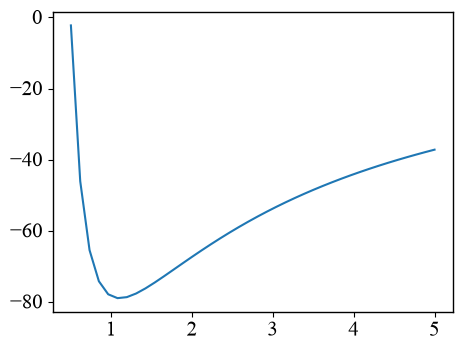

In [ ]:
fig, ax = plt.subplots(figsize = (4, 3))
ax.set_visible = False

ax_kappa = fig.add_axes((0, 0, 1, 1))

ax_kappa.plot(kappas, energy_vals)

def model_function(x, *params):
    return params[0]*x**2 + params[1]*x + params[2]

initial_vals = [1, 1, 1]



